In [21]:
import hashlib
import os
import platform
import uuid
# 修改为自己的学号
STUDENT_ID = 20244080125

CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV")
print(f"[Conda 环境] {CONDA_ENV}")

MACHINE_FP = hashlib.sha256(
    f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号]       {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID]   {RUN_ID}")

[Conda 环境] exp01
[学号]       20244080125
[机器指纹] a3746f08d1f2e9fe
[RUN_ID]   20244080125-a3746f08d1f2e9fe


## 实验 1：围绕半圆定律

C:\Users\曹俊华\AppData\Local\Temp\ipykernel_28056\501287656.py:13: RuntimeWarning: invalid value encountered in sqrt
  return np.where(np.abs(x) <= 2, (1 / (2 * np.pi)) * np.sqrt(4 - x**2), 0.0)


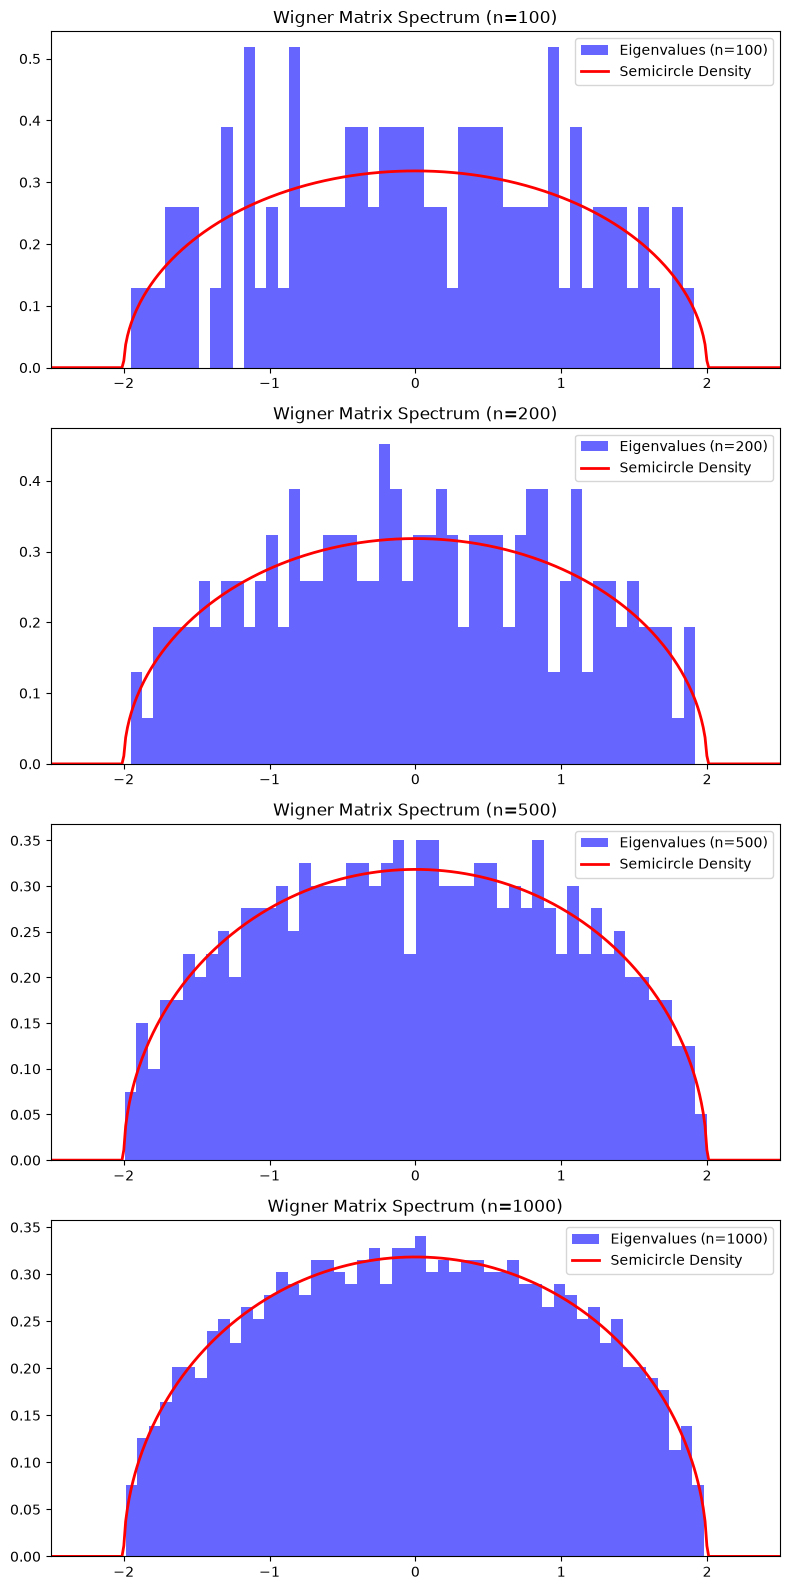

In [22]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import kstest

# 1. 编写 wigner_density(x)
def wigner_density(x):
    """
    计算半圆密度在 x 处的值。
    使用 np.where 实现向量化计算，同时兼容标量和数组输入。
    """
    x = np.asarray(x)
    # 当 |x| <= 2 时，f(x) = (1/(2*pi)) * sqrt(4 - x^2)；否则为 0
    return np.where(np.abs(x) <= 2, (1 / (2 * np.pi)) * np.sqrt(4 - x**2), 0.0)

# 2. 编写 generate_wigner(n)
def generate_wigner(n):
    """
    生成 n x n 的 Wigner 对称随机矩阵。
    """
    if not isinstance(n, (int, np.integer)) or n <= 0:
        raise ValueError("输入必须是正整数")
    
    # 生成标准正态分布矩阵，方差为 1/n，即标准差为 1/sqrt(n)
    std_dev = 1 / np.sqrt(n)
    Z = np.random.normal(0, std_dev, (n, n))
    
    # 构造对称矩阵：取上三角部分 + 上三角（去对角线）的转置
    Z = np.triu(Z) + np.triu(Z, 1).T
    return Z

# 3. 编写 get_spectrum(matrix)
def get_spectrum(matrix):
    """
    返回按非递减顺序排列的特征值数组。
    使用 eigvalsh 专门处理对称/埃尔米特矩阵，速度更快且自动排序。
    """
    return np.linalg.eigvalsh(matrix)

# 4. 画图并验证
def plot_wigner_distributions():
    ns = [100, 200, 500, 1000]
    fig, axes = plt.subplots(4, 1, figsize=(8, 16))
    
    for i, n in enumerate(ns):
        W = generate_wigner(n)
        eigenvalues = get_spectrum(W)
        
        # 标准化直方图 (density=True)
        axes[i].hist(eigenvalues, bins=50, density=True, color='blue', alpha=0.6, label=f'Eigenvalues (n={n})')
        
        # 绘制半圆密度曲线
        x_vals = np.linspace(-2.5, 2.5, 400)
        axes[i].plot(x_vals, wigner_density(x_vals), color='red', linewidth=2, label='Semicircle Density')
        
        axes[i].set_title(f"Wigner Matrix Spectrum (n={n})")
        axes[i].set_xlim(-2.5, 2.5)
        axes[i].legend()
        
        # (可选) Kolmogorov-Smirnov 检验
        # 生成与特征值数量相同的理论分布样本进行对比
        # ks_stat, p_value = kstest(eigenvalues, lambda x: wigner_density(x).cumsum()/wigner_density(x).sum())
        # print(f"n={n}, KS p-value: {p_value:.4f}")

    plt.tight_layout()
    plt.show()

plot_wigner_distributions()

## 实验 2：Conway 的生命游戏

In [23]:
import numpy as np
import matplotlib.pyplot as plt

# 1. 检查有效棋盘
def is_valid_board(board):
    if not isinstance(board, np.ndarray):
        return False
    if board.ndim != 2:
        return False
    if not np.all(np.isin(board, [0, 1])):
        return False
    return True

# 2. 演化一步
def gol_step(board):
    if not is_valid_board(board):
        raise ValueError("无效的棋盘输入")
    
    m, n = board.shape
    neighbors = np.zeros((m, n), dtype=int)
    
    # 使用 np.roll 快速计算 8 个方向的邻居之和
    # np.roll(board, shift, axis) 实现环绕平移
    for i in [-1, 0, 1]:
        for j in [-1, 0, 1]:
            if i == 0 and j == 0:
                continue # 跳过自己
            # roll 行和列
            shifted = np.roll(np.roll(board, i, axis=0), j, axis=1)
            neighbors += shifted
            
    # 根据规则生成新棋盘
    new_board = np.zeros_like(board)
    
    # 规则：活细胞(1)有两个或三个邻居时存活
    new_board[(board == 1) & ((neighbors == 2) | (neighbors == 3))] = 1
    # 规则：死细胞(0)恰好有三个邻居时复活
    new_board[(board == 0) & (neighbors == 3)] = 1
    
    return new_board

# 3. 绘制棋盘
def draw_gol_board(board):
    # 使用 gray_r 反转灰度图，1为黑色，0为白色
    plt.imshow(board, cmap='gray_r', interpolation='nearest')
    plt.xticks([]) # 隐藏 x 轴刻度
    plt.yticks([]) # 隐藏 y 轴刻度
    plt.show()

初始棋盘：


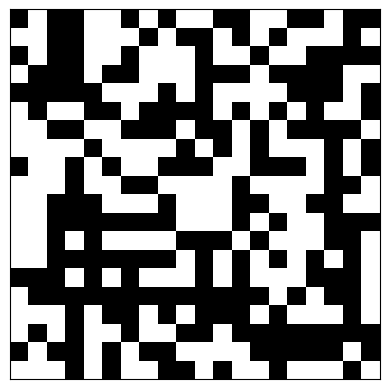

演化一步后的棋盘：


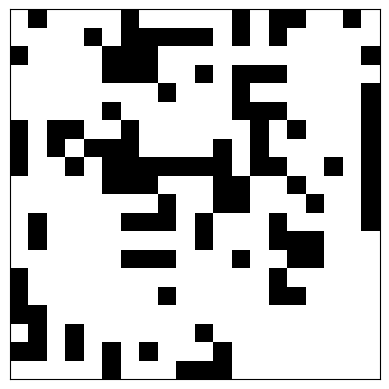

In [24]:
# 简单测试
import numpy as np
import matplotlib.pyplot as plt

# 生成一个 20x20 的随机 0/1 棋盘
test_board = np.random.randint(2, size=(20, 20))

# 画初始棋盘
print("初始棋盘：")
draw_gol_board(test_board)

# 演化一步
next_board = gol_step(test_board)

# 画演化后的棋盘
print("演化一步后的棋盘：")
draw_gol_board(next_board)

## 实验 3：使用 Pandas DataFrame 处理 Iris 数据

In [25]:
import pandas as pd

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)


df = pd.read_csv(r'D:\vscode_python\Iris.csv')

df = df.drop(columns=['Id'])

df.columns = ['SepalLength', 'SepalWidth', 'PetalLength', 'PetalWidth', 'Species']

df['Species'] = df['Species'].str.replace('Iris-', '', regex=False)

cols_to_float = ['SepalLength', 'SepalWidth', 'PetalLength', 'PetalWidth']
df[cols_to_float] = df[cols_to_float].astype(float)

print("--- 任务 1 ---")
print(f"数据集形状 (数据点个数, 列数): {df.shape}")
print(f"列名: {df.columns.tolist()}")
print(f"花卉种类: {df['Species'].unique()}")
print(f"花卉种类数: {df['Species'].nunique()}")

print("\n--- 任务 2 ---")
df.loc[34] = [4.9, 3.1, 1.5, 0.2, "setosa"]
df.loc[37] = [4.9, 3.6, 1.4, 0.1, "setosa"]
print(f"(索引34):\n", df.loc[34].tolist())
print(f"(索引37):\n", df.loc[37].tolist())

print("\n--- 任务 3 ---")
df['Petal.Ratio'] = df['PetalLength'] / df['PetalWidth']
df['Sepal.Ratio'] = df['SepalLength'] / df['SepalWidth']
print("新增的特征列前 5 行：\n", df[['Petal.Ratio', 'Sepal.Ratio']].head())

print("\n--- 任务 4 ---")
df.to_csv('iris_corrected.csv', index=False)
print("已成功保存为 iris_corrected.csv")

print("\n--- 任务 5 ---")
agg_funcs = ['mean', 'median', 'min', 'max', 'std']
summary = df.groupby('Species')[['Petal.Ratio', 'Sepal.Ratio']].agg(agg_funcs)
display(summary)


--- 任务 1 ---
数据集形状 (数据点个数, 列数): (150, 5)
列名: ['SepalLength', 'SepalWidth', 'PetalLength', 'PetalWidth', 'Species']
花卉种类: <StringArray>
['setosa', 'versicolor', 'virginica']
Length: 3, dtype: str
花卉种类数: 3

--- 任务 2 ---
(索引34):
 [np.float64(4.9), np.float64(3.1), np.float64(1.5), np.float64(0.2), 'setosa']
(索引37):
 [np.float64(4.9), np.float64(3.6), np.float64(1.4), np.float64(0.1), 'setosa']

--- 任务 3 ---
新增的特征列前 5 行：
    Petal.Ratio  Sepal.Ratio
0          7.0     1.457143
1          7.0     1.633333
2          6.5     1.468750
3          7.5     1.483871
4          7.0     1.388889

--- 任务 4 ---
已成功保存为 iris_corrected.csv

--- 任务 5 ---


Petal.Ratio                                     Sepal.Ratio                                        
                  mean    median       min   max       std        mean    median       min       max       std
Species                                                                                                       
setosa        6.908000  7.000000  2.666667  15.0  2.854545    1.470188  1.463063  1.268293  1.956522  0.118750
versicolor    3.242837  3.240385  2.666667   4.1  0.312456    2.160402  2.161290  1.764706  2.818182  0.228658
virginica     2.780662  2.666667  2.125000   4.0  0.407367    2.230453  2.169540  1.823529  2.961538  0.246992